# ANA500 Micro-Project 3
Charles Ayuk | November 7, 2026

Source: supplied airline.csv. Repository: [https://github.com/ChalesManyang/ANA500-Micro-Projects](https://github.com/ChalesManyang/ANA500-Micro-Projects)

Run cells in order. Python 3.11+ and requirements.txt are recommended.


## Acquire: load the supplied file and inspect its structure.

In [1]:
# Acquire: load the supplied file and inspect its structure.
from pathlib import Path
import numpy as np
import pandas as pd
# Keep airline.csv beside this notebook, or edit DATA_PATH below.
DATA_PATH = Path('airline.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('../airline.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('../../upload/airline.csv')
raw = pd.read_csv(DATA_PATH)
print('Raw rows and columns:', raw.shape)
print(raw.dtypes.to_string())
print('Missing values:', raw.isna().sum()[raw.isna().sum() > 0].to_dict())



Raw rows and columns: (129880, 25)
Unnamed: 0                             int64
id                                     int64
Gender                                object
Customer Type                         object
Age                                    int64
Type of Travel                        object
Class                                 object
Flight Distance                        int64
Inflight wifi service                  int64
Departure/Arrival time convenient      int64
Ease of Online booking                 int64
Gate location                          int64
Food and drink                         int64
Online boarding                        int64
Seat comfort                           int64
Inflight entertainment                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Inflight service                       int64
Cleanliness         

## Prepare: preserve raw data and create an independent working copy.

In [2]:
# Prepare: preserve raw data and create an independent working copy.
df = raw.copy()
for col in df.select_dtypes(include='object'):
    df[col] = df[col].str.strip()
# The exported row counter is not a passenger attribute.
df = df.drop(columns=[c for c in df if c.startswith('Unnamed:')])
# Check complete duplicate records before considering any removal.
print('Exact duplicate rows:', int(df.duplicated().sum()))
print('Repeated passenger IDs:', int(df['id'].duplicated().sum()))
# Preserve valid zero ratings; their meaning is undocumented in this upload.
# Never assume zero means missing without a data dictionary.
ratings = list(df.loc[:, 'Inflight wifi service':'Cleanliness'].columns)
assert df[ratings].apply(lambda s: s.between(0, 5).all()).all()
assert df['Age'].between(0, 120).all()
assert (df[['Flight Distance', 'Departure Delay in Minutes']].to_numpy() >= 0).all()
print('Rating range:', int(df[ratings].min().min()), int(df[ratings].max().max()))
# Keep missing arrival delays as NaN. Project 3 excludes them as unknown targets.
print(df[['Age','Flight Distance','Departure Delay in Minutes',
          'Arrival Delay in Minutes']].describe().round(2).to_string())
print('Satisfied share (%):', round(df['satisfaction'].eq('satisfied').mean()*100, 2))
# NumPy arrays support explicit missing-value-aware numerical summaries.
arrivals = df['Arrival Delay in Minutes'].to_numpy(dtype=float)
print('Arrival mean / median:', np.nanmean(arrivals), np.nanmedian(arrivals))
print('Known arrival values:', int(np.isfinite(arrivals).sum()))
print('Preparation complete. No missing targets were filled.')



Exact duplicate rows: 0
Repeated passenger IDs: 0
Rating range: 0 5
             Age  Flight Distance  Departure Delay in Minutes  Arrival Delay in Minutes
count  129880.00        129880.00                   129880.00                 129487.00
mean       39.43          1190.32                       14.71                     15.09
std        15.12           997.45                       38.07                     38.47
min         7.00            31.00                        0.00                      0.00
25%        27.00           414.00                        0.00                      0.00
50%        40.00           844.00                        0.00                      0.00
75%        51.00          1744.00                       12.00                     13.00
max        85.00          4983.00                     1592.00                   1584.00
Satisfied share (%): 43.45
Arrival mean / median: 15.09112883918849 0.0
Known arrival values: 129487
Preparation complete. No missing target

## Prepare: select the continuous regression target and prevent leakage.

In [3]:
# Prepare: select the continuous regression target and prevent leakage.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.svm import LinearSVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from threadpoolctl import threadpool_limits
import warnings
from sklearn.exceptions import ConvergenceWarning
import matplotlib.pyplot as plt
threadpool_limits(limits=1)
# A missing outcome cannot be used as a supervised training label.
model_df=df.dropna(subset=['Arrival Delay in Minutes']).copy()
num=['Departure Delay in Minutes','Flight Distance','Age']
cat=['Gender','Customer Type','Type of Travel','Class']
# Exclude satisfaction, IDs and post-flight service ratings.
X=model_df[num+cat]; y=model_df['Arrival Delay in Minutes'].to_numpy()
train_i,remaining_i=train_test_split(np.arange(len(y)),test_size=.30,random_state=42)
val_i,test_i=train_test_split(remaining_i,test_size=.50,random_state=42)
# Fit all preprocessing on training records, then transform validation and test.
prep=ColumnTransformer([
 ('numeric',StandardScaler(),num),
 ('category',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat)])
Xt=prep.fit_transform(X.iloc[train_i]); Xv=prep.transform(X.iloc[val_i])
Xe=prep.transform(X.iloc[test_i])
# Scale y for numerical stability in support vector regression.
ys=StandardScaler().fit(y[train_i].reshape(-1,1))
yt=ys.transform(y[train_i].reshape(-1,1)).ravel()
print('Known outcomes:',len(y))
print('Train / validation / test:',len(train_i),len(val_i),len(test_i))
print('Encoded features:',Xt.shape[1])



Known outcomes: 129487
Train / validation / test: 90640 19423 19424
Encoded features: 12


## Analyze: fit ordinary least squares and tune support vector regression.

In [4]:
# Analyze: fit ordinary least squares and tune support vector regression.
# LinearSVR implements a linear support vector regression model and scales
# better to this dataset than kernel SVR. It is distinct from least squares.
linear=LinearRegression().fit(Xt,y[train_i])
candidates=[];models=[]
for C in [.1,1.,10.]:
 for epsilon in [.01,.1]:
  svr=LinearSVR(C=C,epsilon=epsilon,loss='squared_epsilon_insensitive',
                dual=False,tol=1e-5,max_iter=20000,random_state=42)
  with warnings.catch_warnings(record=True) as caught:
   warnings.simplefilter('always',ConvergenceWarning)
   svr.fit(Xt,yt)
  assert not any(issubclass(w.category,ConvergenceWarning) for w in caught)
  pred=np.maximum(ys.inverse_transform(svr.predict(Xv).reshape(-1,1)).ravel(),0)
  rmse=np.sqrt(mean_squared_error(y[val_i],pred))
  candidates.append({'C':C,'epsilon_scaled':epsilon,'validation_RMSE':rmse})
  models.append(svr)
tuning=pd.DataFrame(candidates)
best_index=int(tuning['validation_RMSE'].argmin());best_svr=models[best_index]
print('Validation tuning results:');print(tuning.round(5).to_string(index=False))
print('Selected parameters:',candidates[best_index])
# Choose the preferred regression model before evaluating the held-out test set.
linear_val=np.maximum(linear.predict(Xv),0)
linear_val_rmse=np.sqrt(mean_squared_error(y[val_i],linear_val))
svr_val_rmse=candidates[best_index]['validation_RMSE']
selected='Linear regression' if linear_val_rmse<=svr_val_rmse else 'Linear SVR'
print('OLS validation RMSE:',linear_val_rmse)
print('Preferred model by validation RMSE:',selected)



Validation tuning results:
   C  epsilon_scaled  validation_RMSE
 0.1            0.01          9.90231
 0.1            0.10         10.04131
 1.0            0.01          9.90234
 1.0            0.10         10.04114
10.0            0.01          9.90234
10.0            0.10         10.04112
Selected parameters: {'C': 0.1, 'epsilon_scaled': 0.01, 'validation_RMSE': np.float64(9.902311740764343)}
OLS validation RMSE: 9.899738157033873
Preferred model by validation RMSE: Linear regression


## Report: compare frozen models and baselines on the held-out test set.

                               MAE      RMSE       R2
Model                                                
Training mean             20.75934  39.16260 -0.00039
Departure equals arrival   5.04031  10.07512  0.93379
Linear regression          5.34868  10.02869  0.93440
Linear SVR                 5.45619  10.03141  0.93436
Test observations with arrival delay >=60 minutes: 1504
Training mean MAE for >=60 minutes: 105.44435644401047
Departure equals arrival MAE for >=60 minutes: 15.46808510638298
Linear regression MAE for >=60 minutes: 15.272792754870357
Linear SVR MAE for >=60 minutes: 15.25678542665698


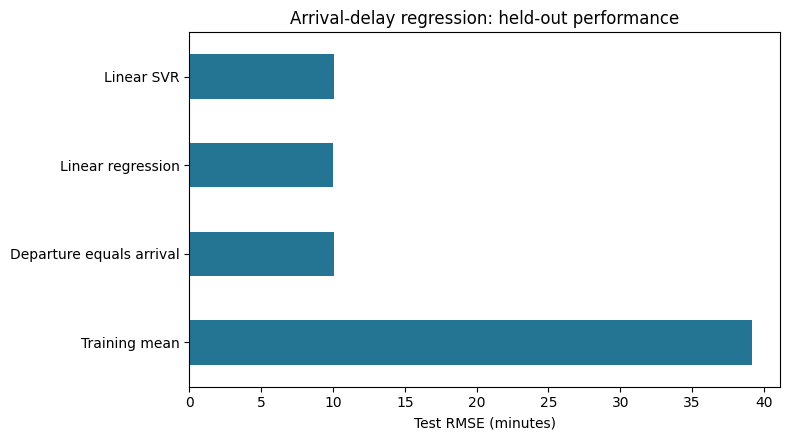

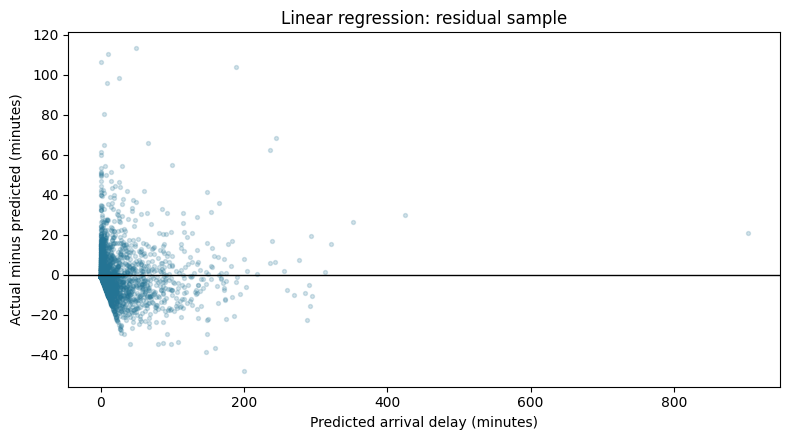

In [5]:
# Report: compare frozen models and baselines on the held-out test set.
# Clip predicted delays at zero consistently because recorded delays are nonnegative.
predictions={
 'Training mean':np.repeat(y[train_i].mean(),len(test_i)),
 'Departure equals arrival':X.iloc[test_i]['Departure Delay in Minutes'].to_numpy(),
 'Linear regression':np.maximum(linear.predict(Xe),0),
 'Linear SVR':np.maximum(ys.inverse_transform(best_svr.predict(Xe).reshape(-1,1)).ravel(),0)}
rows=[]
for name,pred in predictions.items():
 rows.append({'Model':name,'MAE':mean_absolute_error(y[test_i],pred),
              'RMSE':np.sqrt(mean_squared_error(y[test_i],pred)),
              'R2':r2_score(y[test_i],pred)})
metrics=pd.DataFrame(rows).set_index('Model')
print(metrics.round(5).to_string())
# Error in the tail is relevant for passenger communication during major delays.
severe=y[test_i]>=60
print('Test observations with arrival delay >=60 minutes:',int(severe.sum()))
for name,pred in predictions.items():
 print(name,'MAE for >=60 minutes:',mean_absolute_error(y[test_i][severe],pred[severe]))
fig,ax=plt.subplots(figsize=(8,4.5))
metrics['RMSE'].plot.barh(color='#247494',ax=ax)
ax.set(xlabel='Test RMSE (minutes)',ylabel='',title='Arrival-delay regression: held-out performance')
fig.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,4.5))
# Plot a reproducible sample of residuals while reporting metrics for every test row.
rng=np.random.default_rng(42);plot_i=rng.choice(len(test_i),min(4000,len(test_i)),replace=False)
pred=predictions[selected];residual=y[test_i]-pred
ax.scatter(pred[plot_i],residual[plot_i],s=8,alpha=.2,color='#247494')
ax.axhline(0,color='black',linewidth=1)
ax.set(xlabel='Predicted arrival delay (minutes)',ylabel='Actual minus predicted (minutes)',
       title=selected+': residual sample')
fig.tight_layout();plt.show()



## Act: connect the findings to an airline decision.

In [6]:
# Act: connect the findings to an airline decision.
print('Preferred model under the validation-RMSE criterion:',selected)
print('Compare its gain with the simple departure-delay baseline before adding operational complexity.')
print('Run a pilot on dated flight-level records and evaluate later flights separately.')
print('Monitor MAE, RMSE and severe-delay errors by route and flight before customer-facing use.')
print('The survey lacks timestamps, weather, route and flight identifiers.')
print('Passenger-level random splitting may place travelers from one flight in multiple subsets.')
print('The results therefore describe this random holdout, not proven future-flight performance.')
print('Regression predicts associations and does not identify causes of delay.')


Preferred model under the validation-RMSE criterion: Linear regression
Compare its gain with the simple departure-delay baseline before adding operational complexity.
Run a pilot on dated flight-level records and evaluate later flights separately.
Monitor MAE, RMSE and severe-delay errors by route and flight before customer-facing use.
The survey lacks timestamps, weather, route and flight identifiers.
Passenger-level random splitting may place travelers from one flight in multiple subsets.
The results therefore describe this random holdout, not proven future-flight performance.
Regression predicts associations and does not identify causes of delay.
